<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS11/datasetPBL/Praktikum4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from types import SimpleNamespace

# Load dan gabungkan kedua dataset asli
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Filter kategori dengan minimal 20 sampel (setara min_faces_per_person)
counts = df['categories'].value_counts()
valid_cats = counts[counts >= 20].index.tolist()
df_sub = df[df['categories'].isin(valid_cats)].copy()

# Ekstraksi 2.914 fitur (62 x 47) agar dimensi identik dengan citra LFW pada modul
tfidf = TfidfVectorizer(max_features=62 * 47, ngram_range=(1, 2))
X_data = tfidf.fit_transform((df_sub['name'] + " " + df_sub['text'].astype(str))).toarray()

if X_data.shape[1] < 62 * 47:
    X_data = np.pad(X_data, ((0, 0), (0, (62 * 47) - X_data.shape[1])), mode='constant')

target_names = np.array([c.strip("[]'") for c in valid_cats])
cat_to_idx = {c: i for i, c in enumerate(valid_cats)}
y_target = df_sub['categories'].map(cat_to_idx).values

# Bungkus ke dalam objek 'faces' agar struktur atributnya identik dengan modul
faces = SimpleNamespace(
    data=X_data,
    images=X_data.reshape(-1, 62, 47),
    target=y_target,
    target_names=target_names
)

print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Kedai Kopi' 'Kafe' 'Grosir Kopi']
3
(2220, 62, 47)


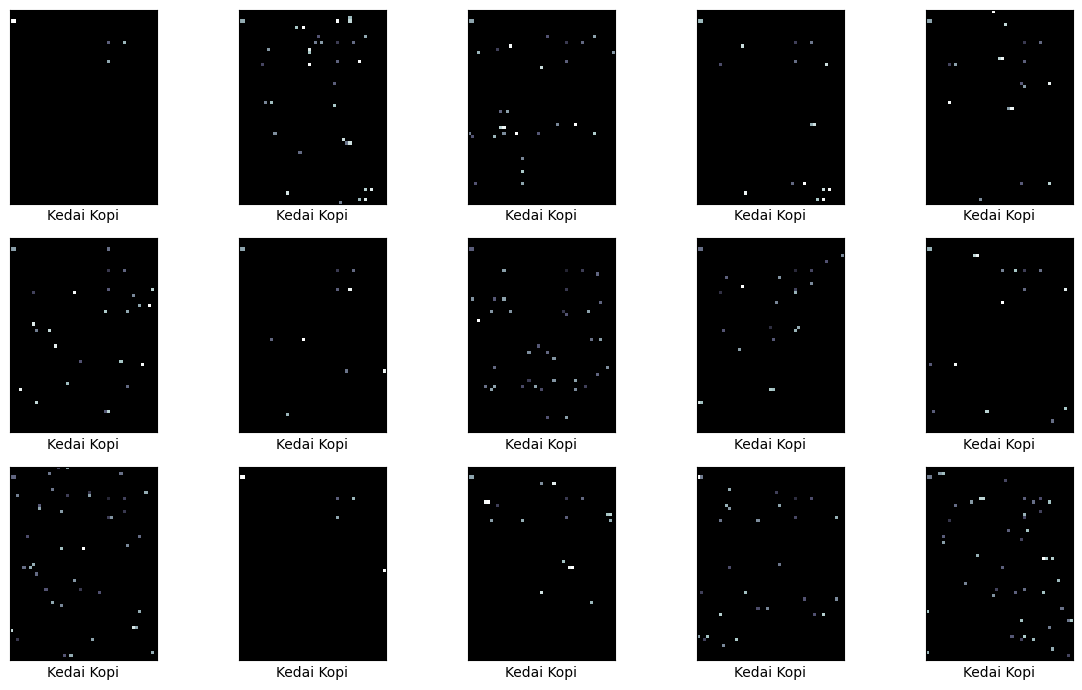

In [8]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5, figsize=(12, 7))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.tight_layout()
plt.show()

In [9]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline untuk menggabungkan reduksi dimensi PCA dan klasifikasi SVC
model = make_pipeline(pca, svc)

In [10]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(
    faces.data, faces.target, random_state=42, stratify=faces.target
)

In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 3min 43s, sys: 1.66 s, total: 3min 45s
Wall time: 2min 26s
{'svc__C': 5, 'svc__gamma': 0.001}
0.9945945945945945


In [12]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

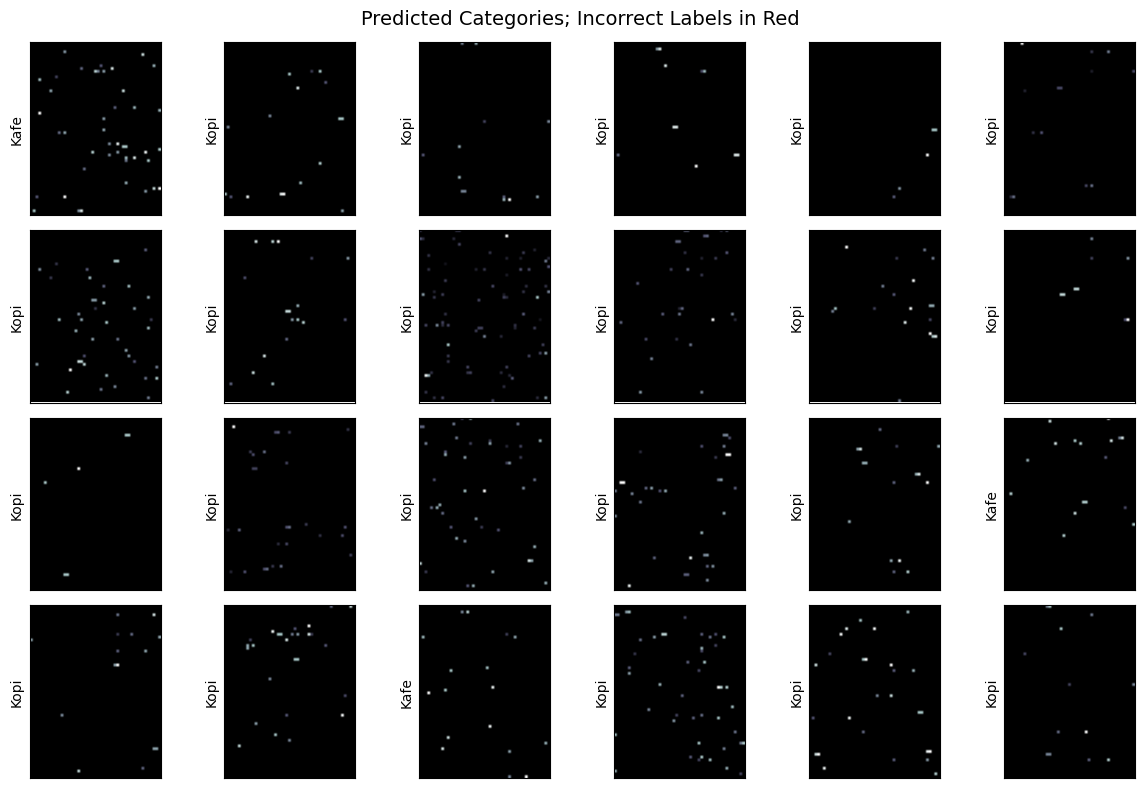

In [13]:
fig, ax = plt.subplots(4, 6, figsize=(12, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Categories; Incorrect Labels in Red', size=14)
plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import classification_report

print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

              precision    recall  f1-score   support

  Kedai Kopi       1.00      1.00      1.00       396
        Kafe       1.00      1.00      1.00       154
 Grosir Kopi       1.00      1.00      1.00         5

    accuracy                           1.00       555
   macro avg       1.00      1.00      1.00       555
weighted avg       1.00      1.00      1.00       555



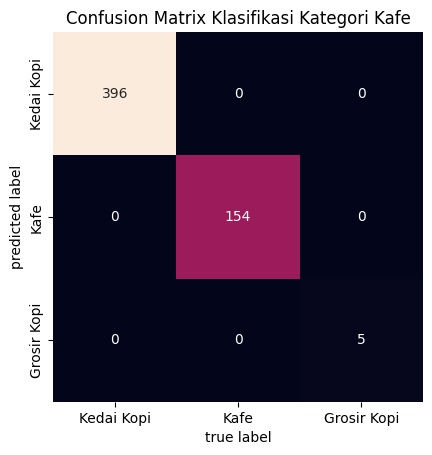

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.title('Confusion Matrix Klasifikasi Kategori Kafe')
plt.show()